In [1]:
import sys
from pathlib import Path

print("Python version:", sys.version.split()[0])
print("Python location:", sys.executable)
print("Working folder:", Path.cwd())

Python version: 3.8.20
Python location: /opt/anaconda3/envs/msis822/bin/python
Working folder: /Users/abdullahhameed/Documents/arabic-ai-detection-msis822


## 1. Load the Dataset

I load the three parts of the dataset and check how many rows each part has.

In [22]:
from datasets import load_dataset
import pandas as pd

dataset = load_dataset(
    "KFUPM-JRCAI/arabic-generated-abstracts"
)

summary = pd.DataFrame([
    {
        "subset": name,
        "rows": len(subset),
        "columns": len(subset.column_names)
    }
    for name, subset in dataset.items()
])

display(summary)
print("Total source rows:", summary["rows"].sum())

,subset,rows,columns
0,by_polishing,2851,5
1,from_title,2963,5
2,from_title_and_content,2574,5


Total source rows: 8388


## 2. Prepare the Text Table

I combine the three subsets and create one row per text.
I preserve the original text, assign the labels, and link related texts using group_id.


In [3]:
frames = []

for name, subset in dataset.items():
    frame = subset.to_pandas()
    frame["generation_method"] = name
    frames.append(frame)

all_data = pd.concat(frames, ignore_index=True)

human_keys = all_data["original_abstract"].str.strip()
all_data["group_id"] = pd.factorize(human_keys, sort=True)[0]

texts = all_data.melt(
    id_vars=["group_id", "generation_method"],
    value_vars=dataset["by_polishing"].column_names,
    var_name="text_source",
    value_name="text_raw"
)

texts["label"] = (
    texts["text_source"] != "original_abstract"
).astype(int)

print("Human texts (0):", (texts["label"] == 0).sum())
print("AI-generated texts (1):", (texts["label"] == 1).sum())
print("Total text entries:", len(texts))
print("Unique groups:", texts["group_id"].nunique())

Human texts (0): 8388
AI-generated texts (1): 33552
Total text entries: 41940
Unique groups: 2992


## 3. Check Data Quality and Label Consistency

I check missing values, blank texts, duplicates, conflicting labels,
and texts shared across multiple groups.
For text matching, I remove leading and trailing whitespace only.

In [4]:
audit = texts.copy()

is_text = audit["text_raw"].map(lambda value: isinstance(value, str))
audit["text_key"] = (
    audit["text_raw"].where(is_text, pd.NA).astype("string").str.strip()
)

valid_texts = audit.loc[
    audit["text_key"].notna()
    & audit["text_key"].ne("").fillna(False)
    & audit["label"].isin([0, 1])
].copy()

labels_per_text = valid_texts.groupby("text_key")["label"].nunique()
groups_per_text = valid_texts.groupby("text_key")["group_id"].nunique()

conflict_keys = labels_per_text[labels_per_text > 1].index
cross_group_keys = groups_per_text[groups_per_text > 1].index

quality_report = pd.Series({
    "total_rows": len(audit),
    "missing_texts": audit["text_raw"].isna().sum(),
    "non_string_texts": (audit["text_raw"].notna() & ~is_text).sum(),
    "blank_texts": audit["text_key"].eq("").sum(),
    "invalid_labels": (~audit["label"].isin([0, 1])).sum(),
    "duplicate_entries_beyond_first": valid_texts.duplicated("text_key").sum(),
    "texts_with_conflicting_labels": len(conflict_keys),
    "texts_in_multiple_groups": len(cross_group_keys)
}).rename_axis("check").to_frame("count")

display(quality_report)

,count
check,
total_rows,41940
missing_texts,0
non_string_texts,0
blank_texts,0
invalid_labels,0
duplicate_entries_beyond_first,5415
texts_with_conflicting_labels,16
texts_in_multiple_groups,1


## 4. Quarantine Conflicting Texts and Remove Duplicates

I keep all occurrences of texts with conflicting labels in a separate
table for review. I then keep one occurrence of each remaining text,
using the trimmed original text for matching.

In [5]:
conflict_mask = valid_texts["text_key"].isin(conflict_keys)

quarantined_texts = valid_texts.loc[conflict_mask].copy()
retained_texts = valid_texts.loc[~conflict_mask].copy()

duplicate_mask = retained_texts.duplicated(
    subset="text_key", keep="first"
)

removed_duplicates = retained_texts.loc[duplicate_mask].copy()
clean_texts = retained_texts.loc[~duplicate_mask].copy()
clean_texts = clean_texts.reset_index(drop=True)

assert clean_texts["text_key"].is_unique
assert not clean_texts["text_key"].isin(conflict_keys).any()
assert (
    len(quarantined_texts) + len(removed_duplicates) + len(clean_texts)
    == len(valid_texts)
)

print("Conflicting text keys:", quarantined_texts["text_key"].nunique())
print("Rows quarantined:", len(quarantined_texts))
print("Duplicate rows removed:", len(removed_duplicates))
print("Remaining text entries:", len(clean_texts))

class_counts = (
    clean_texts["label"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("label")
    .to_frame("text_count")
)

display(class_counts)

Conflicting text keys: 16
Rows quarantined: 61
Duplicate rows removed: 5370
Remaining text entries: 36509


,text_count
label,
0,2976
1,33533


In [ ]:
## 5. Link Related Groups Before Splitting

I link original groups that share the same trimmed text, using all valid
records before quarantine and deduplication. I keep group_id and add
split_group_id so that linked groups stay together in later data splits.

In [6]:
parent = {
    int(group): int(group)
    for group in valid_texts["group_id"].unique()
}

def find_root(group):
    while parent[group] != group:
        parent[group] = parent[parent[group]]
        group = parent[group]
    return group

shared_rows = valid_texts.loc[
    valid_texts["text_key"].isin(cross_group_keys)
]

for groups in shared_rows.groupby("text_key")["group_id"].unique():
    roots = sorted({find_root(int(group)) for group in groups})
    for root in roots[1:]:
        parent[root] = roots[0]

group_map = {
    group: find_root(group)
    for group in parent
}

group_links = valid_texts[["text_key", "group_id"]].copy()
group_links["split_group_id"] = group_links["group_id"].map(group_map)

clean_texts["split_group_id"] = clean_texts["group_id"].map(group_map)

remaining_cross_groups = (
    group_links.groupby("text_key")["split_group_id"].nunique() > 1
).sum()

assert clean_texts["split_group_id"].notna().all()
assert remaining_cross_groups == 0

print("Original groups:", len(group_map))
print("Groups after linking:", len(set(group_map.values())))
print("Split groups in clean data:", clean_texts["split_group_id"].nunique())
print("Texts crossing split groups:", int(remaining_cross_groups))

Original groups: 2992
Groups after linking: 2989
Split groups in clean data: 2989
Texts crossing split groups: 0


## 6. Split the Data by Related Groups

I split the linked groups into training, validation, and test sets
using a fixed random seed. Related texts stay in the same set.

In [7]:
import numpy as np

group_ids = np.sort(clean_texts["split_group_id"].unique())
rng = np.random.default_rng(42)
shuffled_groups = rng.permutation(group_ids)

n_train = int(len(group_ids) * 0.70)
n_validation = int(len(group_ids) * 0.15)

train_groups = shuffled_groups[:n_train]
validation_groups = shuffled_groups[n_train:n_train + n_validation]
test_groups = shuffled_groups[n_train + n_validation:]

split_map = {}
for name, groups in [
    ("train", train_groups),
    ("validation", validation_groups),
    ("test", test_groups),
]:
    split_map.update({group: name for group in groups})

split_data = clean_texts.copy()
split_data["split"] = split_data["split_group_id"].map(split_map)

assert split_data["split"].notna().all()
assert split_data.groupby("split_group_id")["split"].nunique().max() == 1
assert split_data.groupby("text_key")["split"].nunique().max() == 1

train_df = split_data.loc[split_data["split"] == "train"].copy()
validation_df = split_data.loc[split_data["split"] == "validation"].copy()
test_df = split_data.loc[split_data["split"] == "test"].copy()

assert len(train_df) + len(validation_df) + len(test_df) == len(clean_texts)
assert all(
    set(frame["label"].unique()) == {0, 1}
    for frame in [train_df, validation_df, test_df]
)

split_summary = split_data.groupby("split").agg(
    texts=("text_key", "size"),
    groups=("split_group_id", "nunique"),
    human=("label", lambda values: values.eq(0).sum()),
    ai_generated=("label", lambda values: values.eq(1).sum()),
).reindex(["train", "validation", "test"])

split_summary["text_percentage"] = (
    100 * split_summary["texts"] / len(split_data)
).round(2)

display(split_summary)
print("Group and exact-text overlap checks passed.")

,texts,groups,human,ai_generated,text_percentage
split,,,,,
train,25596,2092,2083,23513,70.11
validation,5432,448,446,4986,14.88
test,5481,449,447,5034,15.01


Group and exact-text overlap checks passed.


## 7. Normalize Arabic Text

I create a normalized Arabic version of each text while keeping the
original text. I then check whether normalization creates empty texts,
conflicting labels, or matching texts across data splits.

In [8]:
import re
import unicodedata

diacritics_pattern = re.compile(
    r"[\u0610-\u061A\u064B-\u065F\u0670\u06D6-\u06ED]"
)
non_arabic_pattern = re.compile(r"[^\u0621-\u063A\u0641-\u064A]+")
letter_map = str.maketrans({
    "أ": "ا", "إ": "ا", "آ": "ا", "ٱ": "ا",
    "ؤ": "و", "ئ": "ي", "ى": "ي",
})

def normalize_arabic(text):
    text = unicodedata.normalize("NFKC", text)
    text = diacritics_pattern.sub("", text)
    text = text.translate(letter_map)
    text = non_arabic_pattern.sub(" ", text)
    return " ".join(text.split())

split_data["text_normalized"] = split_data["text_raw"].map(normalize_arabic)

train_df = split_data.loc[split_data["split"] == "train"].copy()
validation_df = split_data.loc[split_data["split"] == "validation"].copy()
test_df = split_data.loc[split_data["split"] == "test"].copy()

nonempty = split_data.loc[split_data["text_normalized"].ne("")]

print("Rows with empty normalized text:",
      int(split_data["text_normalized"].eq("").sum()))
print("Normalized texts with conflicting labels:",
      int(nonempty.groupby("text_normalized")["label"].nunique().gt(1).sum()))
print("Normalized texts in multiple splits:",
      int(nonempty.groupby("text_normalized")["split"].nunique().gt(1).sum()))
print("Text rows after normalization:", len(split_data))

display(split_data[["text_raw", "text_normalized"]].head(2))

Rows with empty normalized text: 1
Normalized texts with conflicting labels: 14
Normalized texts in multiple splits: 0
Text rows after normalization: 36509


,text_raw,text_normalized
0,كثيرا ما ارتبطت المصادر التاريخية في الأندلس خ...,كثيرا ما ارتبطت المصادر التاريخية في الاندلس خ...
1,يعد العامل الثقافي احد ابرز الاسباب التي يعزى ...,يعد العامل الثقافي احد ابرز الاسباب التي يعزي ...


## 8. Review Normalization Collisions

I set aside empty normalized texts and normalized texts that have
conflicting labels. I keep the original records in split_data for
raw-text analysis and review.

In [9]:
empty_mask = split_data["text_normalized"].eq("")

labels_by_normalized_text = (
    split_data.loc[~empty_mask]
    .groupby("text_normalized")["label"]
    .nunique()
)

conflicting_normalized_keys = labels_by_normalized_text[
    labels_by_normalized_text > 1
].index

conflict_mask = split_data["text_normalized"].isin(
    conflicting_normalized_keys
)

excluded_normalized = split_data.loc[
    empty_mask | conflict_mask
].copy()

normalized_eligible = split_data.loc[
    ~(empty_mask | conflict_mask)
].copy()

assert len(excluded_normalized) + len(normalized_eligible) == len(split_data)
assert normalized_eligible["text_normalized"].ne("").all()
assert (
    normalized_eligible.groupby("text_normalized")["label"]
    .nunique().max() == 1
)
assert (
    normalized_eligible.groupby("text_normalized")["split"]
    .nunique().max() == 1
)

print("Empty normalized rows:", int(empty_mask.sum()))
print("Conflicting normalized keys:", len(conflicting_normalized_keys))
print("Rows with conflicting normalized keys:", int(conflict_mask.sum()))
print("Rows eligible for normalized-text analysis:", len(normalized_eligible))
print("Remaining same-label normalized repeats:",
      int(normalized_eligible.duplicated("text_normalized").sum()))

display(
    excluded_normalized.groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
)

Empty normalized rows: 1
Conflicting normalized keys: 14
Rows with conflicting normalized keys: 28
Rows eligible for normalized-text analysis: 36480
Remaining same-label normalized repeats: 1


label,0,1
split,,
test,2,2
train,11,12
validation,1,1


In [11]:
import nltk
print("Download successful:", nltk.download("stopwords", quiet=True))

from nltk.corpus import stopwords
from nltk.stem.isri import ISRIStemmer

print("Arabic stopwords:", len(stopwords.words("arabic")))
print("ISRI example:", ISRIStemmer().stem("المدارس"))

Download successful: True
Arabic stopwords: 754
ISRI example: درس


## 9. Remove Stopwords and Apply ISRI Stemming

I normalize the Arabic stopword list to match the text, remove those
words, and apply ISRI stemming. I keep each text version in a separate
column and check for empty texts and new matching texts.

In [12]:
from functools import lru_cache

arabic_stopwords = {
    normalize_arabic(word)
    for word in stopwords.words("arabic")
}
arabic_stopwords.discard("")

stemmer = ISRIStemmer()

@lru_cache(maxsize=100000)
def stem_token(token):
    return stemmer.stem(token)

def remove_stopwords(text):
    return " ".join(
        word for word in text.split()
        if word not in arabic_stopwords
    )

def stem_text(text):
    return " ".join(
        stem_token(word) for word in text.split()
    )

model_data = normalized_eligible.copy()
model_data["text_no_stopwords"] = (
    model_data["text_normalized"].map(remove_stopwords)
)
model_data["text_stemmed"] = (
    model_data["text_no_stopwords"].map(stem_text)
)

nonempty_stemmed = model_data.loc[
    model_data["text_stemmed"].ne("")
]

assert len(model_data) == len(normalized_eligible)
assert (
    model_data["text_raw"].equals(normalized_eligible["text_raw"])
)

print("Normalized stopword forms:", len(arabic_stopwords))
print("Rows empty after stopword removal:",
      int(model_data["text_no_stopwords"].eq("").sum()))
print("Stemmed texts with conflicting labels:",
      int(nonempty_stemmed.groupby("text_stemmed")["label"].nunique().gt(1).sum()))
print("Stemmed texts in multiple splits:",
      int(nonempty_stemmed.groupby("text_stemmed")["split"].nunique().gt(1).sum()))
print("Processed rows:", len(model_data))

display(
    model_data[
        ["text_normalized", "text_no_stopwords", "text_stemmed"]
    ].head(2)
)

Normalized stopword forms: 623
Rows empty after stopword removal: 0
Stemmed texts with conflicting labels: 5
Stemmed texts in multiple splits: 0
Processed rows: 36480


,text_normalized,text_no_stopwords,text_stemmed
0,كثيرا ما ارتبطت المصادر التاريخية في الاندلس خ...,ارتبطت المصادر التاريخية الاندلس كتب التراجم و...,ربط صدر ارخ دلس كتب رجم هرس رمج وغر درس حية عل...
1,يعد العامل الثقافي احد ابرز الاسباب التي يعزي ...,يعد العامل الثقافي ابرز الاسباب يعزي سقوط الدو...,يعد عمل ثقف برز سبب يعز سقط دول وحد يقل اثر بق...


## 10. Check Stemmed Text Collisions

I set aside stemmed texts with conflicting labels and remove repeated
stemmed texts with the same label. I retain the earlier tables so the
removed records can still be reviewed.

In [13]:
stem_labels = model_data.groupby("text_stemmed")["label"].nunique()
stem_conflict_keys = stem_labels[stem_labels > 1].index

stem_conflict_mask = model_data["text_stemmed"].isin(stem_conflict_keys)
stem_conflict_rows = model_data.loc[stem_conflict_mask].copy()
stem_candidates = model_data.loc[~stem_conflict_mask].copy()

stem_repeat_mask = stem_candidates.duplicated(
    subset="text_stemmed", keep="first"
)
stem_repeat_rows = stem_candidates.loc[stem_repeat_mask].copy()
stem_ready = stem_candidates.loc[~stem_repeat_mask].copy()

assert (
    len(stem_conflict_rows) + len(stem_repeat_rows) + len(stem_ready)
    == len(model_data)
)
assert stem_ready["text_stemmed"].is_unique
assert stem_ready["text_stemmed"].ne("").all()
assert not stem_ready["text_stemmed"].isin(stem_conflict_keys).any()

print("Conflicting stemmed keys:", len(stem_conflict_keys))
print("Rows set aside for stem conflicts:", len(stem_conflict_rows))
print("Repeated stemmed rows removed:", len(stem_repeat_rows))
print("Rows ready for stemmed-text analysis:", len(stem_ready))

display(
    stem_ready.groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
    .reindex(["train", "validation", "test"])
)

Conflicting stemmed keys: 5
Rows set aside for stem conflicts: 10
Repeated stemmed rows removed: 1
Rows ready for stemmed-text analysis: 36469


label,0,1
split,,
train,2068,23498
validation,445,4985
test,443,5030


## 11. Explore Text Length and Vocabulary

I analyze the training texts using their original wording. I measure
Arabic word count, estimated sentence length, vocabulary diversity,
stopword rate, and punctuation count for each class.

In [14]:
def count_sentences(text):
    parts = re.split(r"[.!?؟؛\n]+", text)
    return max(1, sum(bool(part.strip()) for part in parts))

eda_train = train_df[["text_raw", "label"]].copy()
eda_train["words"] = (
    eda_train["text_raw"].map(normalize_arabic).str.split()
)

eda_train["word_count"] = eda_train["words"].map(len)
eda_train["sentence_count"] = (
    eda_train["text_raw"].map(count_sentences)
)
eda_train["avg_words_per_sentence"] = (
    eda_train["word_count"] / eda_train["sentence_count"]
)
eda_train["type_token_ratio"] = eda_train["words"].map(
    lambda words: len(set(words)) / len(words)
    if words else float("nan")
)
eda_train["stopword_rate"] = eda_train["words"].map(
    lambda words: sum(word in arabic_stopwords for word in words) / len(words)
    if words else float("nan")
)
eda_train["punctuation_count"] = eda_train["text_raw"].map(
    lambda text: len(re.findall(r"[،؛,.!?؟:]", text))
)

eda_summary = (
    eda_train.groupby("label")[
        ["word_count", "avg_words_per_sentence",
         "type_token_ratio", "stopword_rate", "punctuation_count"]
    ]
    .agg(["mean", "median"])
    .round(2)
)

print("Training texts analyzed:", len(eda_train))
print("Texts without Arabic words:",
      int(eda_train["word_count"].eq(0).sum()))
display(eda_summary)

Training texts analyzed: 25596
Texts without Arabic words: 1


word_count        avg_words_per_sentence        type_token_ratio         \
            mean median                   mean median             mean median   
label                                                                           
0         119.03  110.0                  55.08   45.0             0.79   0.80   
1         101.03   98.0                  21.22   20.5             0.77   0.78   

      stopword_rate        punctuation_count         
               mean median              mean median  
label                                                
0              0.24   0.24             11.00   10.0  
1              0.21   0.21              9.84    9.0

## 12. Compare Function Words and Punctuation

I compare selected Arabic function words and punctuation marks between
the two classes. I report counts per 1,000 Arabic words to account for
the difference in the number of texts.

In [15]:
from collections import Counter

function_words = [
    normalize_arabic(word)
    for word in ["في", "من", "على", "إلى", "أن", "كان", "التي", "الذي"]
]
punctuation_marks = ["،", "؛", ".", ",", "؟", "?", "!", ":"]

function_rows = []
punctuation_rows = []

for label, class_name in [(0, "Human"), (1, "AI-generated")]:
    class_data = eda_train.loc[eda_train["label"] == label]
    total_words = class_data["word_count"].sum()

    word_counts = Counter(
        word
        for words in class_data["words"]
        for word in words
    )
    mark_counts = Counter(
        mark
        for text in class_data["text_raw"]
        for mark in text
        if mark in punctuation_marks
    )

    for word in function_words:
        function_rows.append({
            "item": word,
            "class": class_name,
            "per_1000_words": 1000 * word_counts[word] / total_words
        })

    for mark in punctuation_marks:
        punctuation_rows.append({
            "item": mark,
            "class": class_name,
            "per_1000_words": 1000 * mark_counts[mark] / total_words
        })

function_table = (
    pd.DataFrame(function_rows)
    .pivot(index="item", columns="class", values="per_1000_words")
    .round(2)
)
punctuation_table = (
    pd.DataFrame(punctuation_rows)
    .pivot(index="item", columns="class", values="per_1000_words")
    .round(2)
)

print("Function words per 1,000 Arabic words:")
display(function_table)
print("Punctuation marks per 1,000 Arabic words:")
display(punctuation_table)

Function words per 1,000 Arabic words:


class,AI-generated,Human
item,,
التي,6.88,9.82
الذي,1.89,4.00
الي,18.68,12.95
ان,8.81,8.69
علي,24.45,16.93
في,43.55,35.13
كان,0.70,1.92
من,19.86,28.76


Punctuation marks per 1,000 Arabic words:


class,AI-generated,Human
item,,
!,0.00,0.01
",",0.09,0.98
.,47.67,26.97
:,1.57,3.50
?,0.00,0.00
،,47.75,57.70
؛,0.14,2.46
؟,0.13,0.76


## 13. Find Common Words and Bigrams

I find the most frequent content words and adjacent two-word phrases
in each training class. I exclude stopwords and report frequencies
per 1,000 Arabic words.

In [16]:
from collections import Counter

def is_content_word(word):
    return len(word) >= 3 and word not in arabic_stopwords

unigram_rows = []
bigram_rows = []

for label, class_name in [(0, "Human"), (1, "AI-generated")]:
    class_data = eda_train.loc[eda_train["label"] == label]
    total_words = class_data["word_count"].sum()
    unigram_counts = Counter()
    bigram_counts = Counter()

    for words in class_data["words"]:
        unigram_counts.update(
            word for word in words if is_content_word(word)
        )
        bigram_counts.update(
            (first, second)
            for first, second in zip(words, words[1:])
            if is_content_word(first) and is_content_word(second)
        )

    for word, count in unigram_counts.most_common(12):
        unigram_rows.append({
            "class": class_name,
            "word": word,
            "count": count,
            "per_1000_words": round(1000 * count / total_words, 2)
        })

    for (first, second), count in bigram_counts.most_common(10):
        bigram_rows.append({
            "class": class_name,
            "bigram": first + " " + second,
            "count": count,
            "per_1000_words": round(1000 * count / total_words, 2)
        })

top_unigrams = pd.DataFrame(unigram_rows)
top_bigrams = pd.DataFrame(bigram_rows)

print("Top words by class:")
display(top_unigrams)
print("Top adjacent two-word phrases by class:")
display(top_bigrams)

Top words by class:


,class,word,count,per_1000_words
0,Human,الدراسة,1390,5.61
1,Human,خلال,1086,4.38
2,Human,البحث,577,2.33
3,Human,وقد,522,2.11
4,Human,الجزاير,487,1.96
5,Human,العربية,458,1.85
6,Human,الجزايري,414,1.67
7,Human,وذلك,405,1.63
8,Human,اهم,393,1.59
9,Human,اللغة,383,1.54


Top adjacent two-word phrases by class:


,class,bigram,count,per_1000_words
0,Human,الورقة البحثية,145,0.58
1,Human,اللغة العربية,138,0.56
2,Human,المنهج الوصفي,116,0.47
3,Human,الكلمات المفتاحية,115,0.46
4,Human,المشرع الجزايري,112,0.45
5,Human,توصلت الدراسة,75,0.30
6,Human,تسليط الضوء,70,0.28
7,Human,عينة الدراسة,70,0.28
8,Human,جهة اخري,69,0.28
9,Human,هدفت الدراسة,64,0.26


## 14. Create Arabic Word Clouds

I create one Arabic word cloud for each training class using frequent content words. To display Arabic letters correctly, this step requires `wordcloud`, `arabic-reshaper`, and `python-bidi`.

If these packages are not installed, run the following command in a Jupyter code cell:

`%pip install wordcloud==1.9.4 arabic-reshaper==3.0.0 python-bidi==0.4.2`

I save the combined figure under `reports/figures/`.

In [18]:
%pip install wordcloud==1.9.4 arabic-reshaper==3.0.0 python-bidi==0.4.2

Note: you may need to restart the kernel to use updated packages.


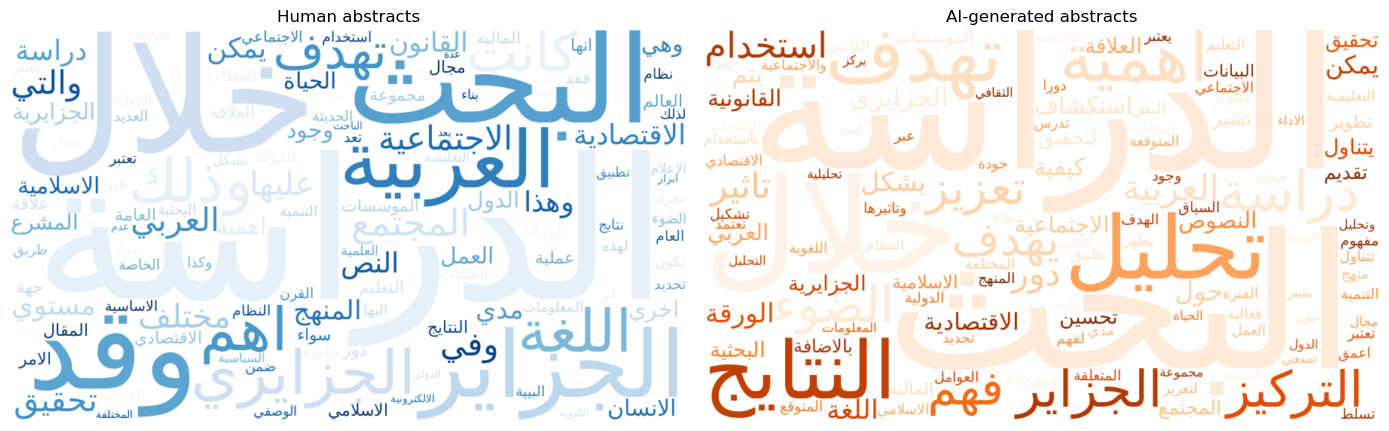

Saved figure: /Users/abdullahhameed/Documents/arabic-ai-detection-msis822/reports/figures/phase2_wordclouds.png


In [19]:
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib import font_manager
from wordcloud import WordCloud
import arabic_reshaper
from bidi.algorithm import get_display

font_path = font_manager.findfont(
    font_manager.FontProperties(family="DejaVu Sans"),
    fontext="ttf"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, label, title, colors in [
    (axes[0], 0, "Human abstracts", "Blues"),
    (axes[1], 1, "AI-generated abstracts", "Oranges"),
]:
    word_counts = Counter(
        word
        for words in eda_train.loc[eda_train["label"] == label, "words"]
        for word in words
        if is_content_word(word)
    )
    shaped_frequencies = {
        get_display(arabic_reshaper.reshape(word)): count
        for word, count in word_counts.most_common(120)
    }
    assert shaped_frequencies

    cloud = WordCloud(
        font_path=font_path,
        width=900,
        height=520,
        background_color="white",
        colormap=colors,
        max_words=120,
        random_state=42,
        prefer_horizontal=1.0,
    ).generate_from_frequencies(shaped_frequencies)

    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(title)
    ax.axis("off")

fig.tight_layout()
figure_path = Path("reports/figures/phase2_wordclouds.png")
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved figure:", figure_path.resolve())

## 15. Compare Text Lengths

I compare the word counts of human and AI-generated abstracts in the training data. I use percentages because the two classes have different numbers of texts.

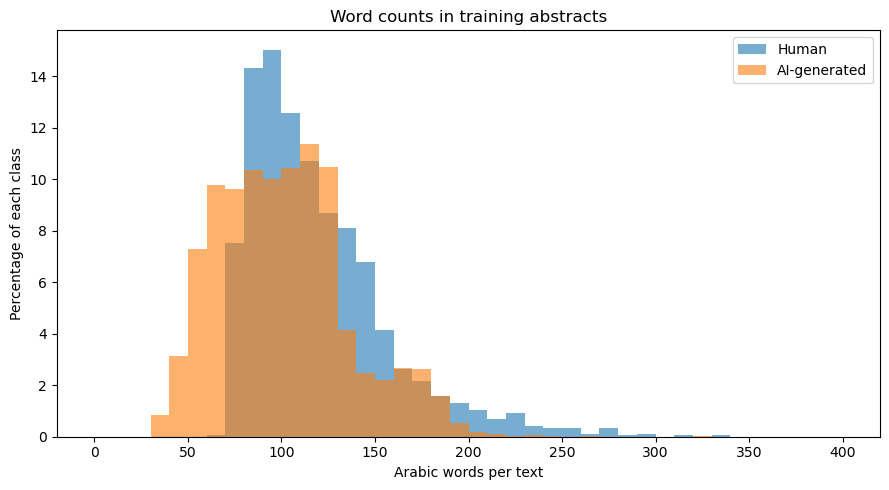

Saved figure: /Users/abdullahhameed/Documents/arabic-ai-detection-msis822/reports/figures/phase2_word_counts.png
Texts over 400 words: 5


In [20]:
from pathlib import Path
import matplotlib.pyplot as plt

human_lengths = eda_train.loc[eda_train["label"] == 0, "word_count"]
ai_lengths = eda_train.loc[eda_train["label"] == 1, "word_count"]

fig, ax = plt.subplots(figsize=(9, 5))
bins = range(0, 401, 10)

ax.hist(
    human_lengths,
    bins=bins,
    weights=[100 / len(human_lengths)] * len(human_lengths),
    alpha=0.6,
    label="Human",
)
ax.hist(
    ai_lengths,
    bins=bins,
    weights=[100 / len(ai_lengths)] * len(ai_lengths),
    alpha=0.6,
    label="AI-generated",
)

ax.set(
    title="Word counts in training abstracts",
    xlabel="Arabic words per text",
    ylabel="Percentage of each class",
)
ax.legend()
fig.tight_layout()

figure_path = Path("reports/figures/phase2_word_counts.png")
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=160)
plt.show()

print("Saved figure:", figure_path.resolve())
print("Texts over 400 words:", (human_lengths > 400).sum() + (ai_lengths > 400).sum())

## 16. Save Prepared Data

I save the cleaned texts with their group-based train, validation, and test assignments. I also save the texts prepared for the stemming experiment. Five training texts exceed the 400-word range shown in the word-count figure.

In [21]:
from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

for split_name in ("train", "validation", "test"):
    cleaned = split_data.loc[split_data["split"] == split_name].copy()
    stemmed = stem_ready.loc[stem_ready["split"] == split_name].copy()

    cleaned.to_parquet(output_dir / f"{split_name}_clean.parquet", index=False)
    stemmed.to_parquet(output_dir / f"{split_name}_stemmed.parquet", index=False)

    print(f"{split_name}: {len(cleaned)} cleaned, {len(stemmed)} stemmed")

print("Saved to:", output_dir.resolve())

train: 25596 cleaned, 25566 stemmed
validation: 5432 cleaned, 5430 stemmed
test: 5481 cleaned, 5473 stemmed
Saved to: /Users/abdullahhameed/Documents/arabic-ai-detection-msis822/data/processed
